# 01 - Exploratory Data Analysis 

In this notebook we load the data, clean the target and look at the variables (Section 5.1 of the project). The code is in `src/`, here we only call it and look at the results.

In [1]:
import sys, os
sys.path.append(os.path.join('..', 'src'))
import pandas as pd
from IPython.display import Image, display
import config
from data_loader import load_and_clean_data
pd.set_option('display.max_rows', 100)
from eda import run_eda

## 1. Loading and cleaning
We remove duplicates and the rows with PM2.5 missing, <= 0 or >= 500 before doing anything else.

In [2]:
df, log = load_and_clean_data()
df.head()

1. Loading data...


   Original shape: (41718, 15)
   Date range: 2016-11-25 -> 2026-04-06
   Stations: 94 names, 98 ids
   Latitude: 36.13 to 43.53, Longitude: -5.66 to 9.14
   Duplicates removed: 0 full rows, 2 on (date, station)
   Removed bad pm25 rows: 735 (missing: 0, <=0: 727, >=500: 8)
   Cleaning done. New shape: (40981, 15)



,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
0,2024-01-31,2024-01-31 00:00:00,78,43.530285,5.440912,5.456260,998.054461,0.816807,-0.719029,0.000062,0.030421,0.147437,0.100333,16.308696,AIX CENTRE ECOLE ART
1,2024-02-03,2024-02-03 00:00:00,78,43.530285,5.440912,7.291314,992.638431,0.883795,-1.323595,0.000071,0.030895,0.157438,0.036000,12.254167,AIX CENTRE ECOLE ART
2,2024-02-05,2024-02-05 00:00:00,78,43.530285,5.440912,7.382460,989.565975,1.285037,-1.362412,0.000098,0.034206,0.145901,0.035000,20.750000,AIX CENTRE ECOLE ART
3,2024-02-11,2024-02-11 00:00:00,78,43.530285,5.440912,7.340276,964.619917,4.365722,-1.965241,0.000047,0.031679,0.188570,0.074333,2.879167,AIX CENTRE ECOLE ART
4,2024-02-13,2024-02-13 00:00:00,78,43.530285,5.440912,6.712459,983.336981,0.971022,-1.463131,0.000074,0.036099,0.162014,0.036500,10.283333,AIX CENTRE ECOLE ART


In [3]:
run_eda(df, log)
eda = pd.read_csv(os.path.join(config.RESULTS_DIR, 'Exploratory_Data.csv'))

2. Running comprehensive EDA...


   All EDA plots and CSVs saved to figures/ and results/ successfully!



## 2. Dataset audit and cleaning counts

In [4]:
eda[eda.section.isin(['cleaning', 'audit'])]

,section,variable,metric,value
0,cleaning,all,raw_rows,41718
1,cleaning,all,raw_columns,15
2,cleaning,all,full_row_duplicates_removed,0
3,cleaning,all,date_station_duplicates_removed,2
4,cleaning,all,date_lat_lon_duplicates,0
5,cleaning,all,date_id_duplicates,0
6,cleaning,all,pm25_missing_removed,0
7,cleaning,all,pm25_le_0_removed,727
8,cleaning,all,pm25_ge_500_removed,8
9,cleaning,all,clean_rows,40981


## 3. Summary statistics
min, max, mean, std, quartiles, skewness and kurtosis for the target and the 8 predictors.

In [5]:
summary = eda[eda.section == 'summary'].pivot(index='variable', columns='metric', values='value')
summary.astype(float).round(4)

metric,25%,50%,75%,count,kurtosis,max,mean,min,skewness,std
variable,,,,,,,,,,
AOD,0.0800,0.1280,0.1940,40981.0,246.8528,5.4750,0.1487,0.0000,7.6116,0.1061
CO,0.0290,0.0314,0.0338,38574.0,13.7687,0.0976,0.0316,0.0131,1.3983,0.0039
NO2,0.0001,0.0001,0.0001,38574.0,9.1770,0.0005,0.0001,0.0000,2.1226,0.0000
O3,0.1340,0.1405,0.1510,38533.0,2.2778,0.2293,0.1435,0.1039,1.1505,0.0145
pm25,4.6727,7.8500,12.0867,40981.0,651.6462,484.9815,9.4576,0.0067,17.8288,9.7299
pressure_mb,987.9864,997.7315,1005.3668,40981.0,0.7142,1033.6622,993.8174,930.3171,-1.0869,17.1804
temperature_celsius,12.9653,18.4933,23.7873,40981.0,-0.9712,34.8658,18.2717,-1.2791,-0.1022,6.3862
wind_u,-0.9848,0.2058,1.6842,40981.0,1.0341,9.6617,0.3435,-11.0987,-0.1778,2.5279
wind_v,-0.7309,0.0430,0.6617,40981.0,4.3891,8.4864,-0.1787,-10.8600,-1.2767,1.3856


## 4. Missing values and outliers
We only count outliers (IQR rule and |z| > 3), we don't delete them because high PM2.5 days can be real pollution episodes.

In [6]:
eda[eda.section.isin(['missing', 'outliers'])].pivot(index='variable', columns='metric', values='value')

metric,iqr_outliers,missing_count,missing_pct,zscore_gt3
variable,,,,
AOD,1114,0,0.0,299
CO,572,2407,5.87,257
NO2,2061,2407,5.87,731
O3,1219,2448,5.97,463
pm25,1613,0,0.0,255
pressure_mb,3179,0,0.0,72
temperature_celsius,0,0,0.0,4
wind_u,2133,0,0.0,281
wind_v,2233,0,0.0,753


In [7]:
eda[eda.section.isin(['target', 'high_correlation'])]

,section,variable,metric,value
239,target,pm25,pct_above_25,2.98
240,target,pm25,pct_above_50,0.29
241,high_correlation,all,n_pairs_abs_r_gt_0.9,0


NO2/CO/O3 missing values by station (top 10 stations with the most missing NO2):

In [8]:
ms = eda[eda.section == 'missing_by_station'].pivot(index='metric', columns='variable', values='value').astype(float)
ms.sort_values('NO2', ascending=False).head(10)

variable,CO,NO2,O3
metric,,,
FR03030,55.48,55.48,56.18
FR03006,47.31,47.31,47.69
FR03043,46.47,46.47,47.21
FR03029,45.85,45.85,46.64
VALÈNCIA-PISTA DE SILLA,21.48,21.48,21.90
QUART DE POBLET,21.48,21.48,21.90
ALMASSORA-C. P. OCHANDO,21.11,21.11,21.38
VALÈNCIA-POLITÈCNIC,20.94,20.94,21.35
ALGAR DE PALÀNCIA,20.75,20.75,21.01


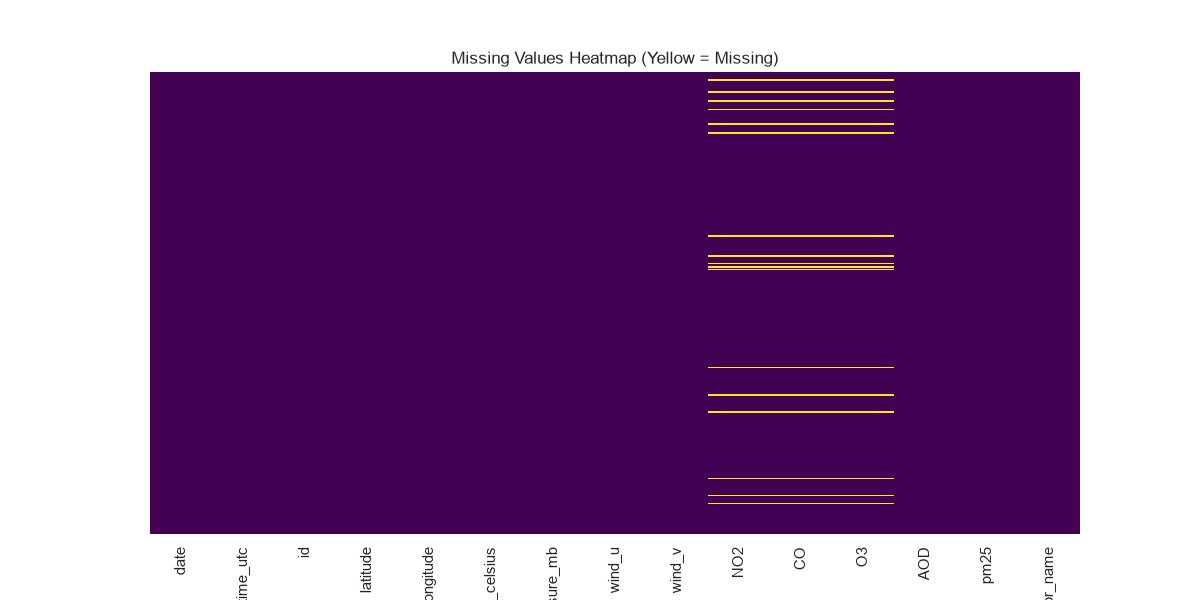

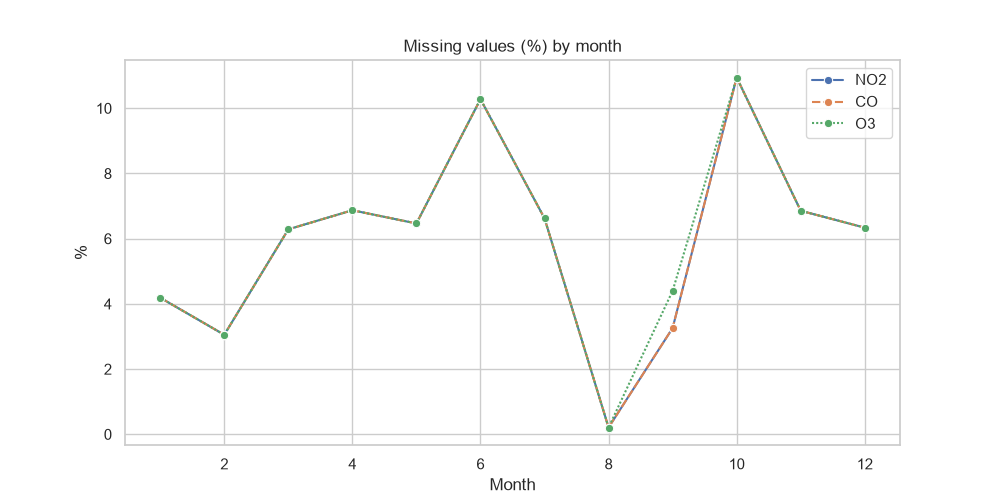

In [9]:
display(Image(os.path.join(config.FIGURES_DIR, 'missingness_heatmap.png')))
display(Image(os.path.join(config.FIGURES_DIR, 'missing_by_month.png')))

## 5. Distributions
PM2.5 is very skewed to the right (a lot of small values and a few very high days). Only about 3% of the days are above 25 ug/m3 and 0.3% above 50 ug/m3, so the RMSE will be pushed up by these rare days. The log1p version looks much more normal.

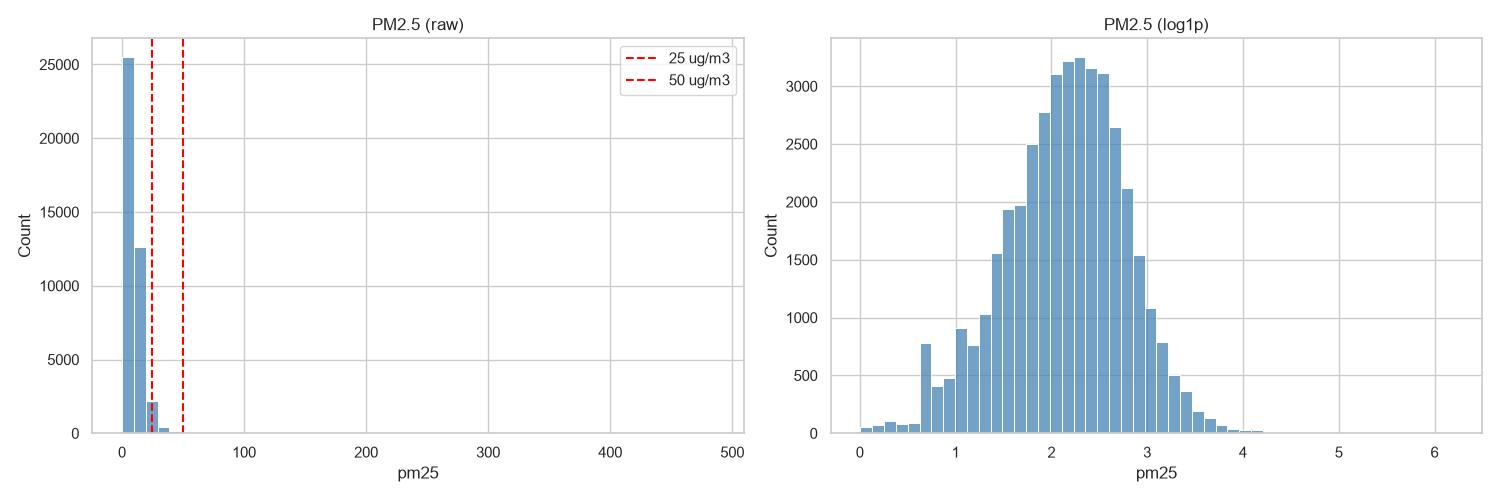

In [10]:
display(Image(os.path.join(config.FIGURES_DIR, 'pm25_distribution.png')))

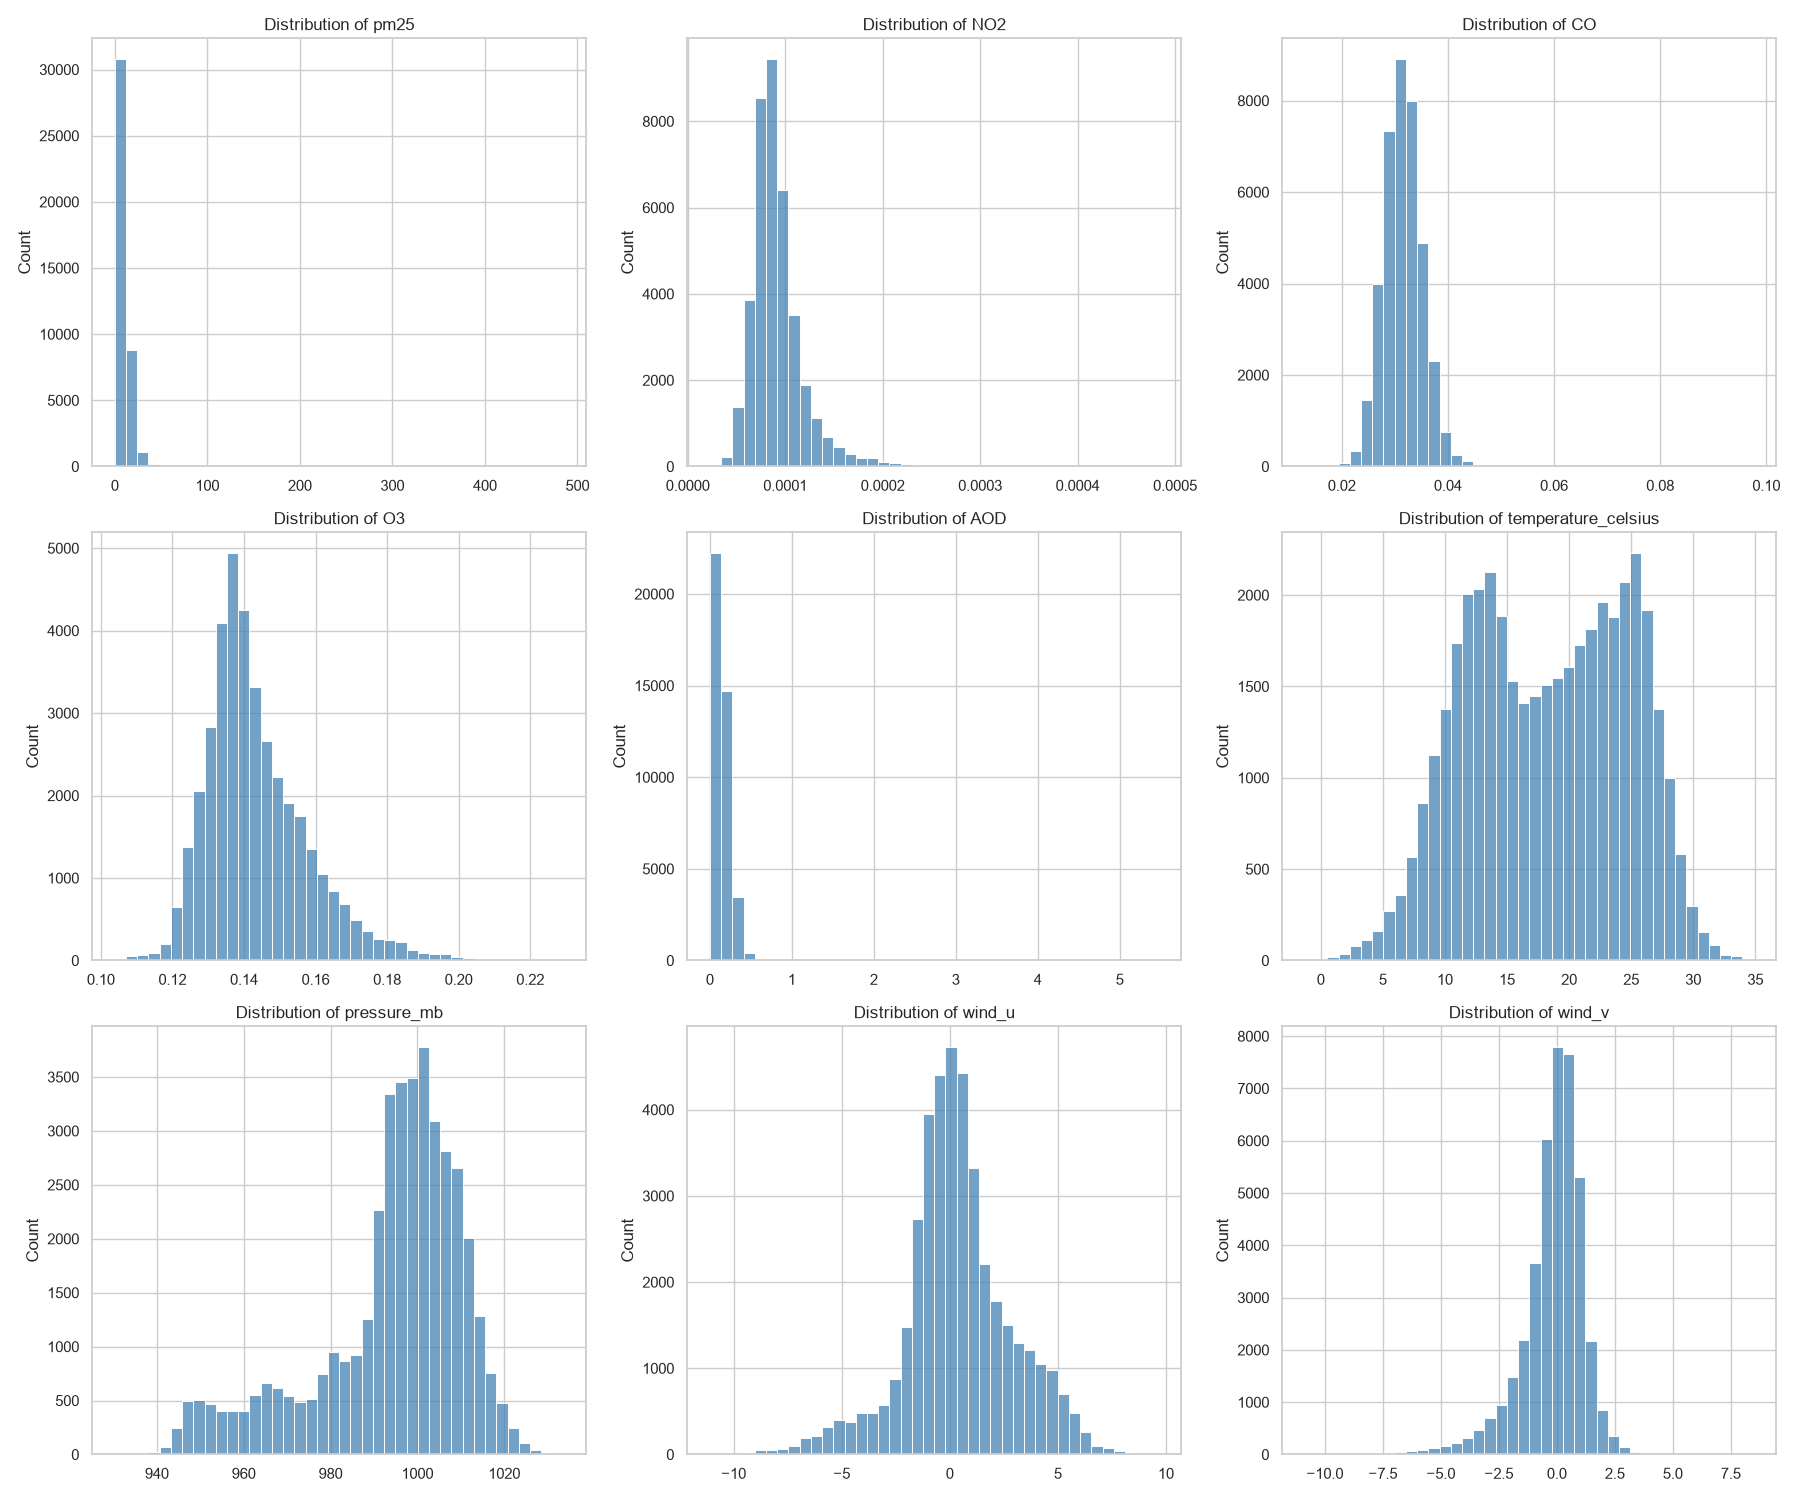

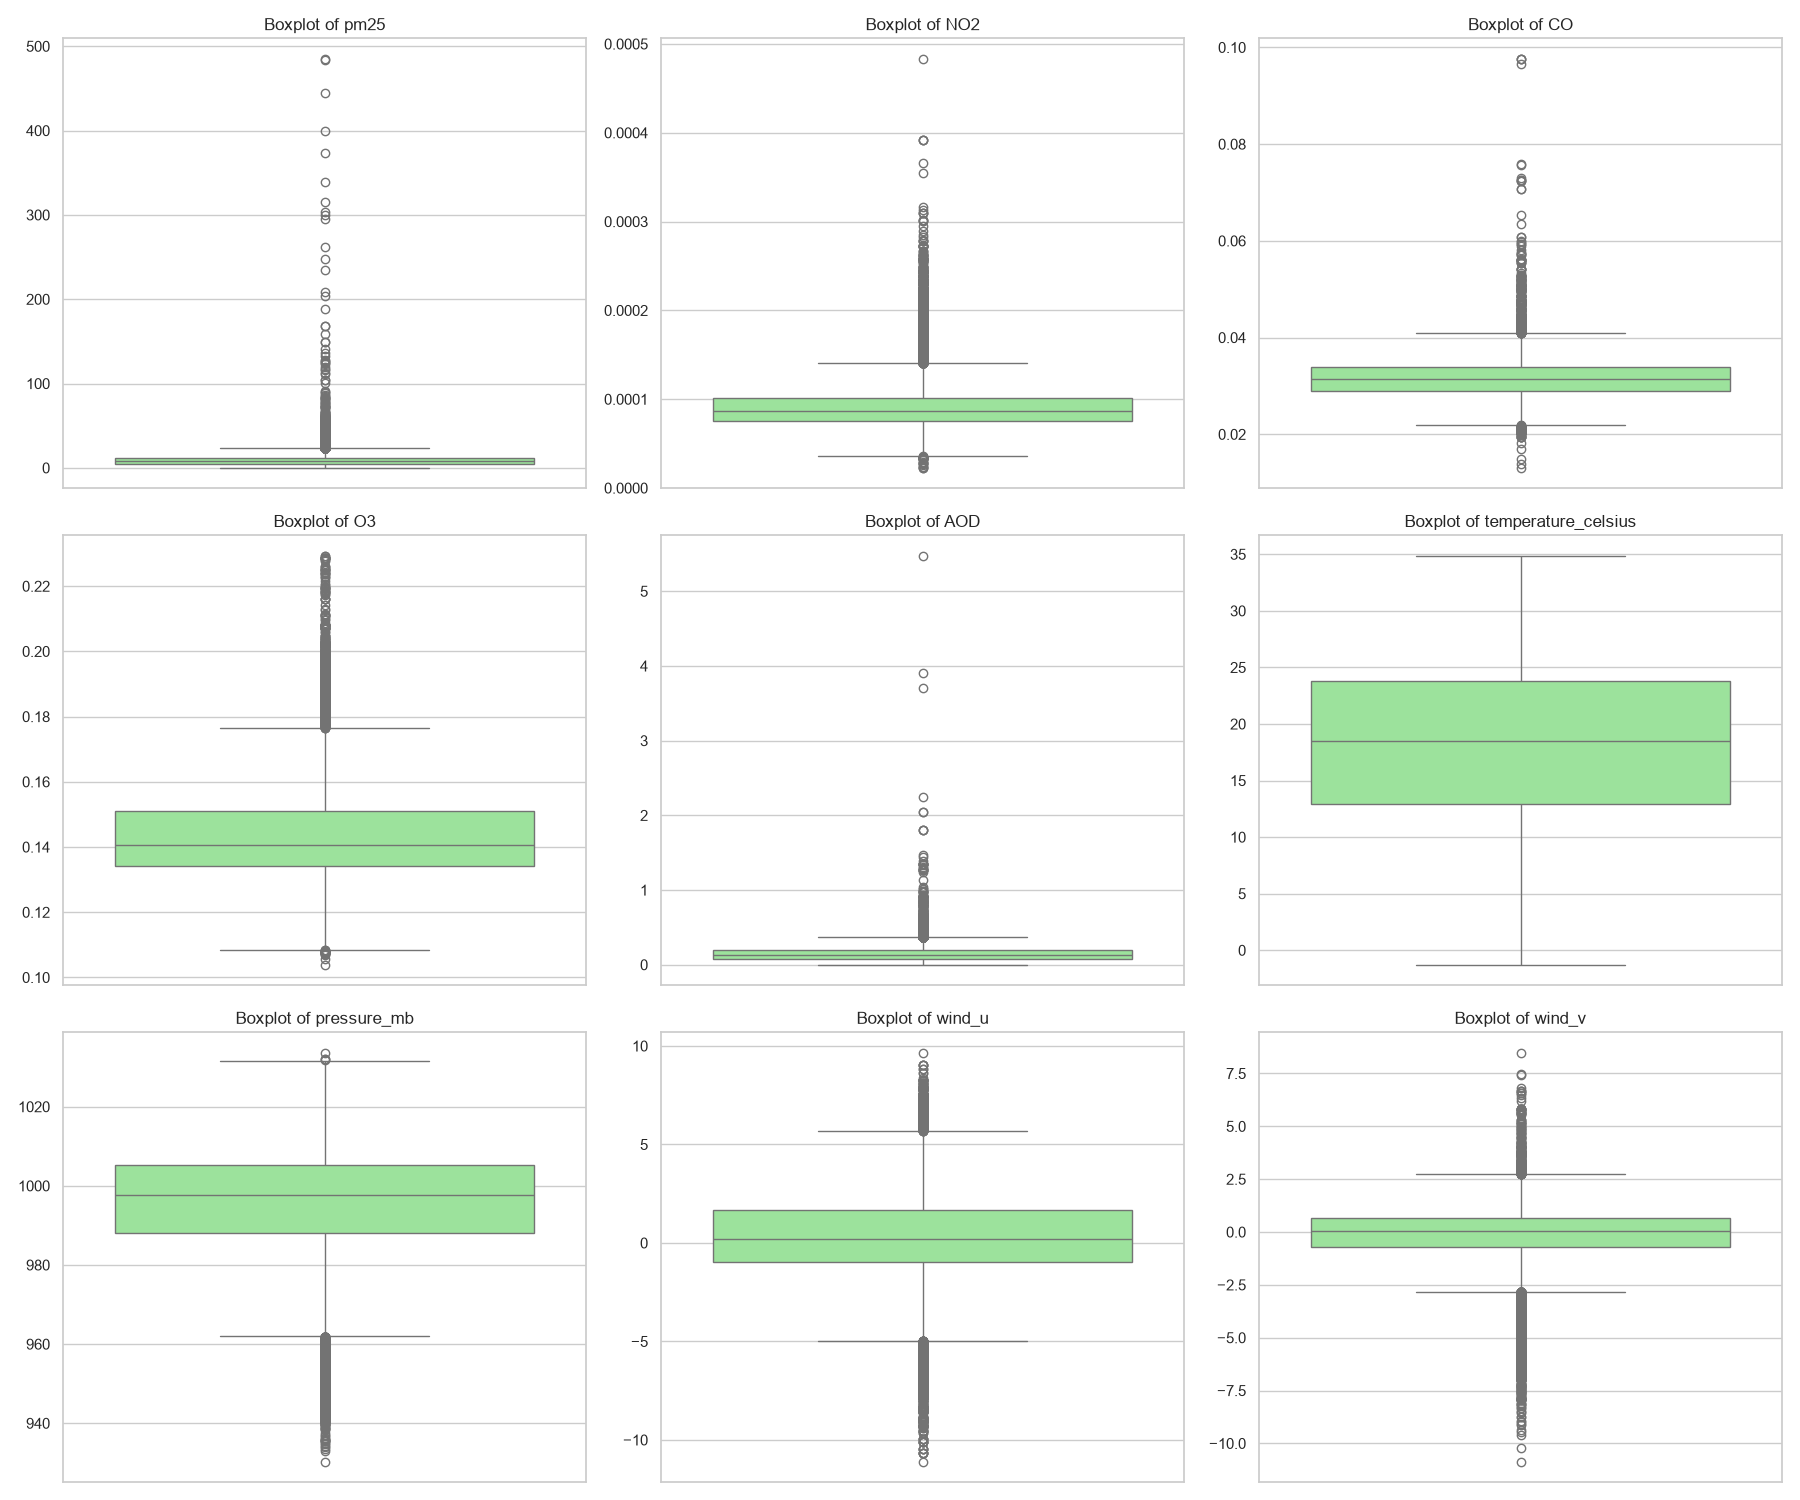

In [11]:
display(Image(os.path.join(config.FIGURES_DIR, 'eda_histogrammes.png')))
display(Image(os.path.join(config.FIGURES_DIR, 'boxplots_all_features.png')))

## 6. Correlations
No pair of predictors has |r| > 0.9, so we keep all of them for now (no VIF/PCA needed at this stage).

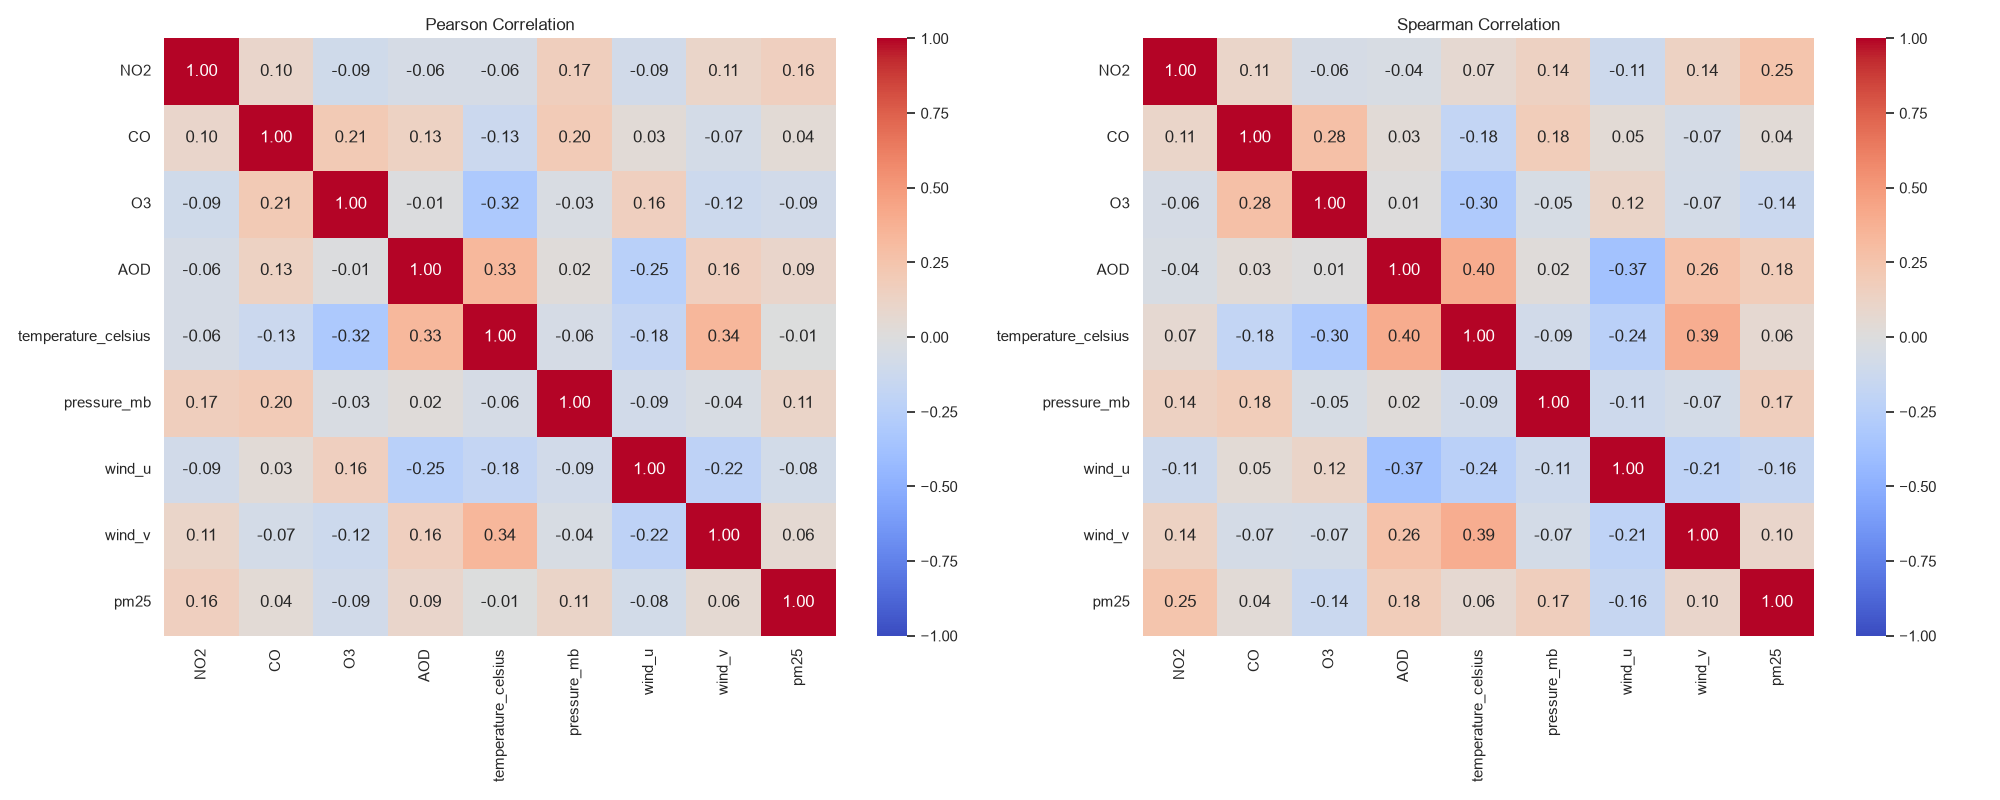

In [12]:
display(Image(os.path.join(config.FIGURES_DIR, 'correlation_matrix.png')))

## 7. PM2.5 - AOD relationship by season and wind
The link between AOD and PM2.5 is not the same all year: it is stronger in winter and weaker in spring, and stronger when the wind is high.

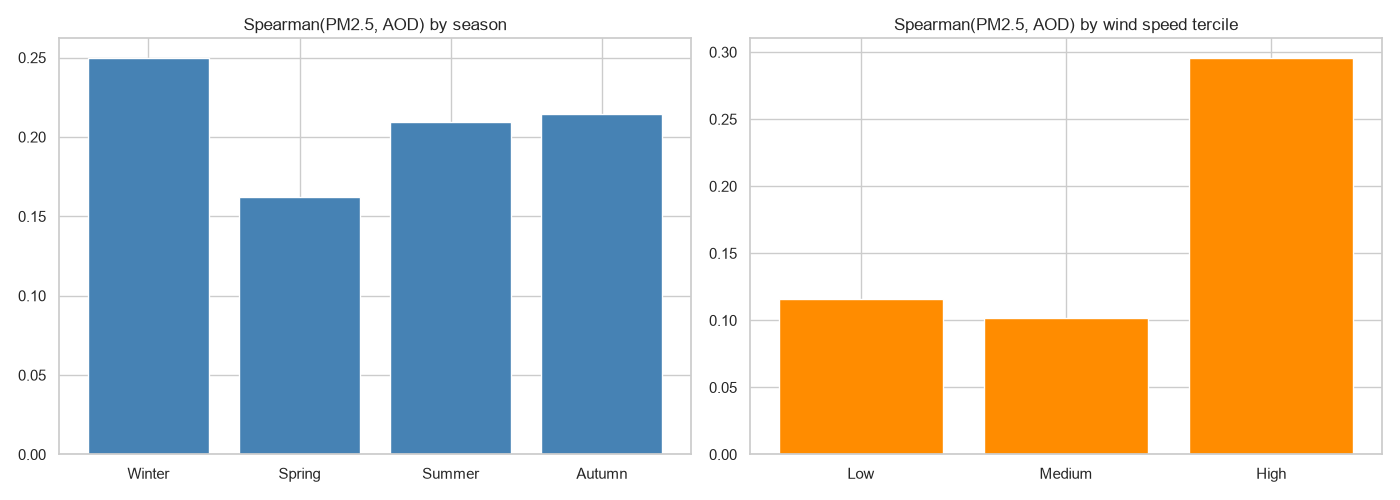

In [13]:
display(Image(os.path.join(config.FIGURES_DIR, 'pm25_aod_by_season.png')))

Scatter of PM2.5 vs AOD: the cloud is very wide, the correlation is weak (about 0.2), so AOD alone is not enough.

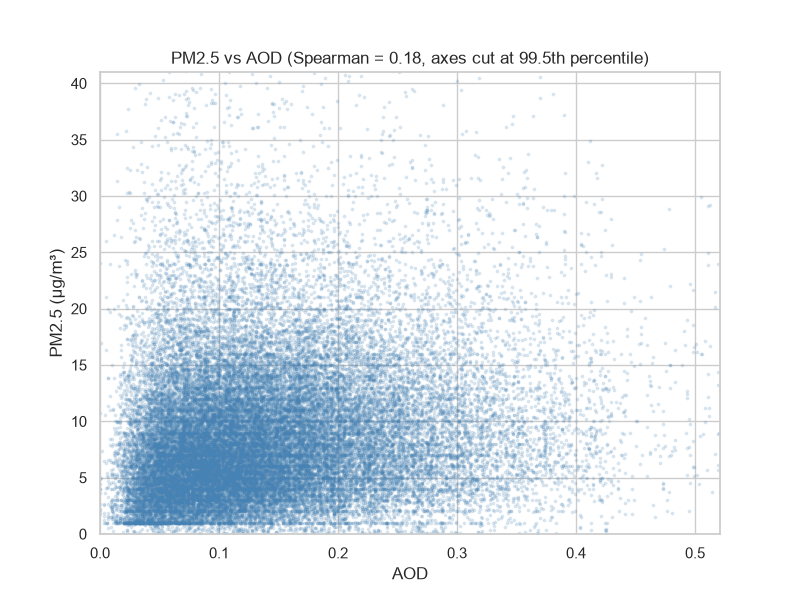

In [14]:
display(Image(os.path.join(config.FIGURES_DIR, 'pm25_vs_aod_scatter.png')))

The correlation computed inside each station is also very different from one station to another:

In [15]:
eda[eda.section == 'corr_by_station'].pivot(index='variable', columns='metric', values='value')

metric,n_stations,spearman_max,spearman_median,spearman_min
variable,,,,
AOD,76,0.5457,0.2007,-0.1819
NO2,76,0.5608,0.2593,-0.0084
pressure_mb,76,0.4929,0.17,-0.2167
temperature_celsius,76,0.5749,0.1423,-0.4166


## 8. Stations
Number of records for each station (we keep all 91 stations, see README).

In [16]:
eda[eda.section == 'records_by_station'][['metric', 'value']].rename(columns={'metric': 'station', 'value': 'n_records'}).head(15)

,station,n_records
22,CENMO1,1042
23,CENCA1,1037
24,MOMPEAN,894
25,ALBALAT DELS TARONGERS,798
26,SAGUNT CEA,797
27,CARRANQUE,784
28,TORREVIEJA,780
29,ALGAR DE PALÀNCIA,771
30,BENICASSIM,770
31,ALCORA,761


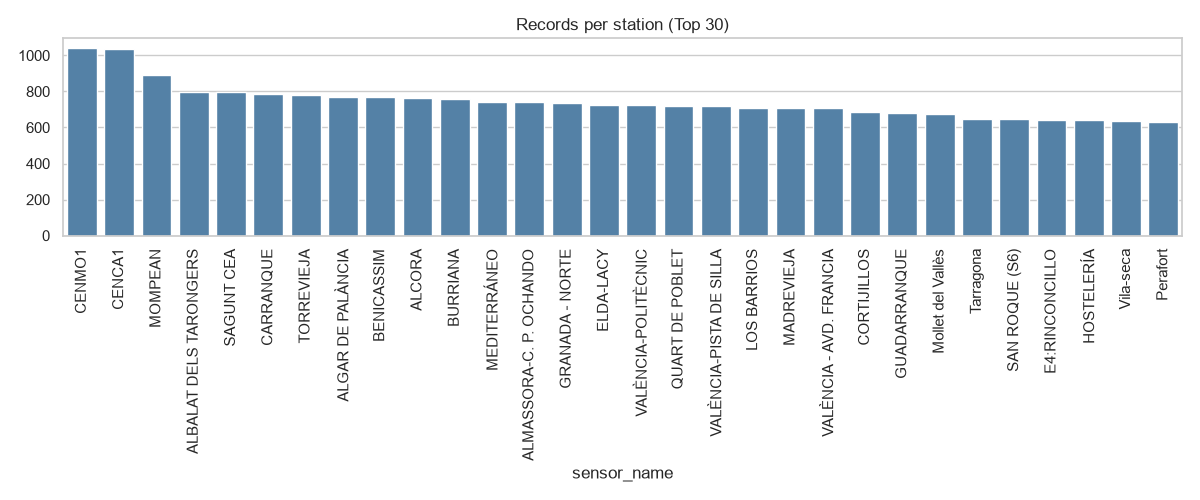

In [17]:
display(Image(os.path.join(config.FIGURES_DIR, 'records_per_station.png')))

Map of the stations. The color scale stops at the 95th percentile because Gibraltar (36 records, median 44) would hide the other differences.

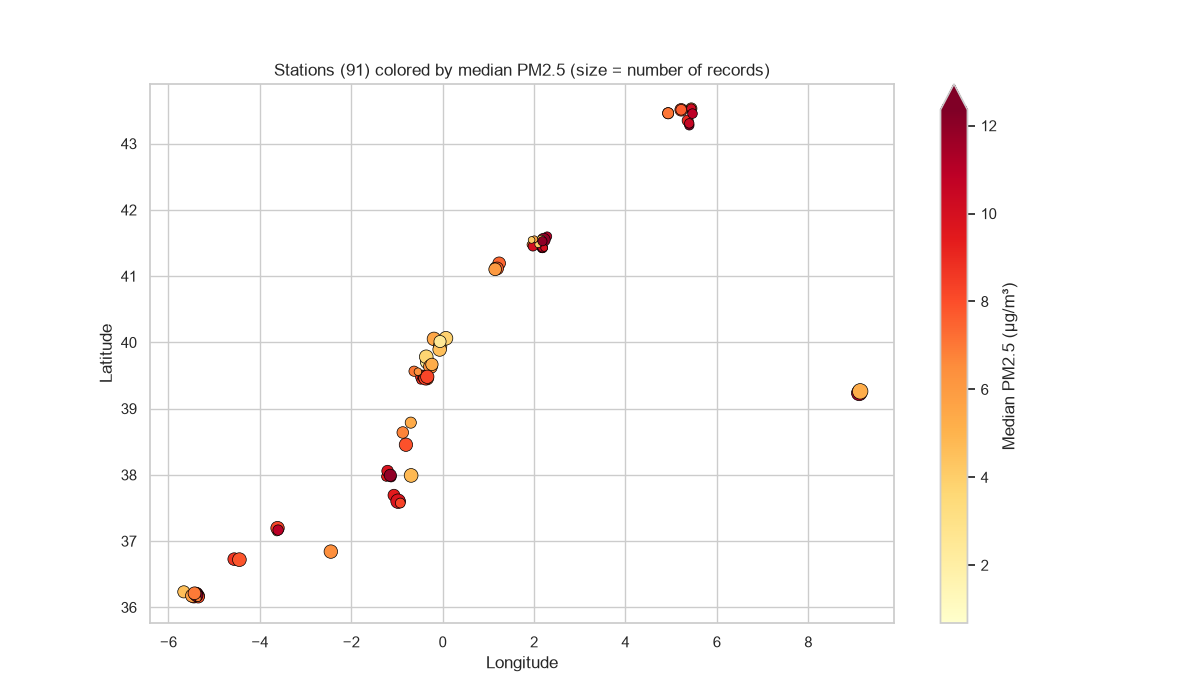

In [18]:
display(Image(os.path.join(config.FIGURES_DIR, 'stations_map.png')))